# Lab 3. 실험 — 기준 조건 위에서 하나씩 바꿔 보기

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kehdgus9434/sonic-vibe-coding-lab/blob/main/notebooks/lab3_experiments.ipynb)

**주제:** 완성된 SONIC 폐루프로 강건성·한계 실험

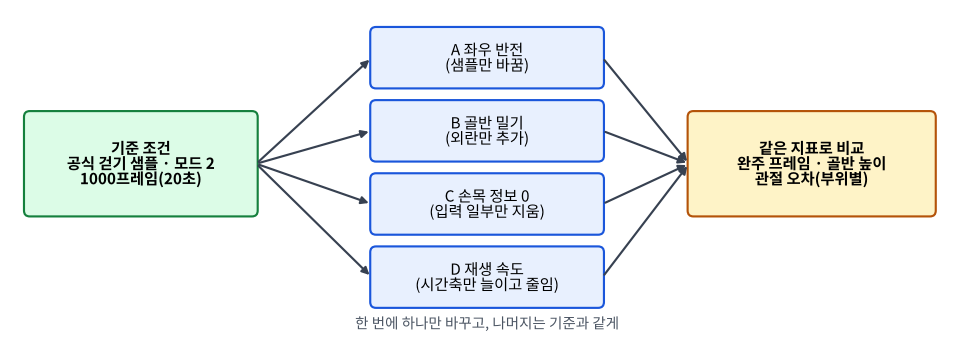

Lab 2까지 완성한 폐루프를 기준으로, **한 번에 하나씩만 바꾸는 실험**을 합니다. 먼저 정책이 하는 일을 보여 주는 기준 3조건을 비교하고, 좌우 반전 · 골반 밀기 · 손목 정보 제거 · 재생 속도 변경이 걷기에 어떤 영향을 주는지 같은 지표로 비교합니다.

## 오늘의 산출물

1. 기준 3조건 비교 (정책 없음 / G1 모드 0 / SMPL 모드 2)
2. 부위별 관절 오차
3. 변형 실험 A–D와 결과 표·그래프·영상

## 실습 방식

- 대부분의 코드는 이미 작성되어 있습니다. **`TODO` 표시가 있는 셀의 빈칸만** 채우면 됩니다.
- `########### Answer #############` 사이의 `None` 또는 `_____`를 알맞은 값·식으로 바꾸세요. 채우지 않고 실행하면 `AssertionError: TODO …` 또는 `NameError: name '_____' is not defined`가 납니다.
- 각 TODO 아래의 `check.…` / `assert`가 바로 ✅/❌로 알려 줍니다. ❌이면 메시지를 읽고 빈칸을 다시 보세요.
- 막히면 AI(ChatGPT·Claude·Gemini, Colab의 Gemini)에게 **그 빈칸 하나**와 [`docs/01_contract.md`](https://github.com/kehdgus9434/sonic-vibe-coding-lab/blob/main/docs/01_contract.md)를 함께 주고 물어봐도 됩니다.
- 마지막의 **해석 질문**은 정답 제출용이 아니라 스스로 정리하기 위한 질문입니다.
- ⚠️ 이 실습의 어떤 출력도 실물 로봇에 보내지 않습니다.

# 0. 환경 설정

In [ ]:
#@title 실습 환경 준비 — 수정하지 말고 실행하세요 (처음 1–2분)
REPO = "https://github.com/kehdgus9434/sonic-vibe-coding-lab"
import os, sys, subprocess
from pathlib import Path
if Path("/content").exists():                              # Google Colab
    LAB_DIR = Path("/content/sonic-vibe-coding-lab")
    if not LAB_DIR.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, str(LAB_DIR)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(LAB_DIR / "requirements-colab.txt")], check=True)
else:                                                      # 로컬 Jupyter (저장소 안에서 실행)
    LAB_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(LAB_DIR)
sys.path.insert(0, str(LAB_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as R
import sonic_lab
from sonic_lab import check, reference as ref, render, analysis
analysis.korean_font()
lab = sonic_lab.start()      # 공식 모델·로봇·걷기 샘플 준비 (lab.policy / lab.sim / lab.motion / lab.contract)

# 1. 기준 3조건
| 조건 | 정책 입력 | 의미 |
|---|---|---|
| `reference_pd` | 없음 — 참조 관절각을 PD로 그대로 재생 | 정책 없이도 걸을 수 있나? |
| `0` (G1 모드) | G1 참조 관절각 | 로봇 모션을 따라감 |
| `2` (SMPL 모드) | 사람 관절 위치 | 사람 모션을 따라감 |

지표: **완주 프레임**(골반 높이 0.35 m 아래 또는 크게 기울면 넘어짐으로 판정), **최저 골반 높이**, **관절 RMSE**(참조 G1 관절각과의 차이).

In [ ]:
N = 1000   # 20초
baseline = {f"cond:{m}": ref.run_physics(lab.sim, lab.policy, lab.motion, mode=m, max_frames=N) for m in ["reference_pd", 0, 2]}
display(analysis.table(baseline))
analysis.plot(baseline, lab);

# 2. 부위별 관절 오차
관절 RMSE 하나만 보면 어디가 나쁜지 알 수 없습니다. G1의 29관절을 **MuJoCo 순서**(계약서 2절)로 세 부위로 나눠 봅니다.

| 번호 | 관절 |
|---|---|
| 0–5 | 왼다리 (hip ×3, knee, ankle ×2) |
| 6–11 | 오른다리 |
| 12–14 | 허리 (yaw, roll, pitch) |
| 15–21 | 왼팔 (shoulder ×3, elbow, wrist ×3) |
| 22–28 | 오른팔 |

In [ ]:
# TODO 1: 세 부위의 관절 번호 범위를 채우세요. range(시작, 끝)에서 끝 번호는 포함되지 않습니다.
# Hint:
# - 다리는 12개, 허리는 3개, 팔·손목은 14개입니다.
#
########### Answer #############
GROUPS = {
    "다리": range(_____, _____),
    "허리": range(_____, _____),
    "팔·손목": range(_____, _____),
}
########### Answer #############
check.body_groups(GROUPS)

def joint_error_by_group(arrays):
    ids = np.minimum(np.arange(len(arrays["qpos"])) + 1, len(lab.motion.times) - 1)
    err = np.degrees(np.abs(arrays["qpos"][:, lab.sim.qaddr] - lab.motion.g1_q[ids]))
    return {g: round(float(err[:, list(r)].mean()), 2) for g, r in GROUPS.items()}

group_df = pd.DataFrame({label: joint_error_by_group(baseline[label][1]) for label in ["cond:0", "cond:2"]}).T
display(group_df)
group_df.T.plot.bar(figsize=(7, 3), rot=0, title="부위별 평균 관절 오차 (deg)"); plt.show()

# 3. 변형 실험
기준(모드 2, 1000프레임)에서 **하나만** 바꿉니다. 네 실험의 빈칸을 채우고 실행하면 마지막에 한 표로 비교합니다.

### A. 좌우 반전
공식 저장소에는 같은 걷기를 좌우 반전한 샘플(`_M`)도 있습니다.

In [ ]:
import dataclasses
experiments = {"기준 (모드 2)": baseline["cond:2"]}

# TODO 2: 좌우 반전 샘플을 불러오도록 인자를 채우세요.
#
########### Answer #############
mirrored = lab.load_motion(mirrored=_____)
########### Answer #############
experiments["A 좌우 반전"] = ref.run_physics(lab.sim, lab.policy, mirrored, mode=2, max_frames=N)
display(analysis.table({k: experiments[k] for k in ["기준 (모드 2)", "A 좌우 반전"]}))

### B. 골반 밀기
걷는 도중(5초 시점부터) 골반에 수평 힘을 가합니다. 힘은 **크기(N)와 지속 시간(초)** 으로 정합니다.
참고: 400 N으로 0.2초 밀면 버팁니다. 넘어지게 만들려면 얼마나 세게, 오래 밀어야 할까요?

In [ ]:
def push(force_n, duration_s, start_frame=250):
    frames = int(round(duration_s * 50))
    def on_frame(frame, sim):
        active = start_frame <= frame < start_frame + frames
        sim.data.xfrc_applied[sim.pelvis_id, :3] = [force_n, 0, 0] if active else 0   # 끝나면 반드시 0으로
    return on_frame

# TODO 3: 밀어 볼 힘(N)과 지속 시간(초)을 정하세요. (정답 없음 — 여러 번 바꿔 실행해 보세요)
#
########### Answer #############
FORCE_N = None
DURATION_S = None
########### Answer #############
assert FORCE_N is not None and DURATION_S is not None, "TODO 3: 두 값을 채우세요."
label_b = f"B 밀기 {FORCE_N}N×{DURATION_S}s"
experiments[label_b] = ref.run_physics(lab.sim, lab.policy, lab.motion, mode=2, max_frames=N, on_frame=push(FORCE_N, DURATION_S))
display(analysis.table({k: experiments[k] for k in ["기준 (모드 2)", label_b]}))

### C. 손목 정보 지우기
사람 동작 데이터에는 로봇 손목 각도가 없는 경우가 많습니다(원본 연구의 ETRI 데이터도 0으로 대체). 손목 입력을 0으로 바꾸면 어떻게 될까요?

In [ ]:
# TODO 4: 손목 6관절 입력(lab.motion.wrists_il, shape (T, 6))을 같은 크기의 0 배열로 바꾸세요.
# Hint:
# - np.zeros_like(배열)은 같은 shape의 0 배열을 만듭니다.
#
########### Answer #############
no_wrist = dataclasses.replace(lab.motion, wrists_il=_____)
########### Answer #############
assert np.allclose(no_wrist.wrists_il, 0) and no_wrist.wrists_il.shape == lab.motion.wrists_il.shape, "TODO 4: 같은 shape의 0 배열이어야 합니다."
experiments["C 손목 0"] = ref.run_physics(lab.sim, lab.policy, no_wrist, mode=2, max_frames=N)
display(analysis.table({k: experiments[k] for k in ["기준 (모드 2)", "C 손목 0"]}))
for k in ["기준 (모드 2)", "C 손목 0"]:
    print(k, joint_error_by_group(experiments[k][1]))

### D. 재생 속도 바꾸기
참조 동작을 빠르게(>1) 또는 느리게(<1) 재생합니다. 관절 오차는 **같은 속도로 바꾼 참조**와 비교합니다.

In [ ]:
from scipy.interpolate import interp1d
from scipy.spatial.transform import Slerp

def retime(motion, speed):
    """참조 동작 전체를 speed배 빠르기로 다시 샘플링 (위치는 선형, 회전은 SLERP)."""
    src = motion.times
    new = np.arange(int(np.floor(src[-1] / speed * 50 + 1e-8)) + 1) / 50
    s = np.clip(new * speed, 0, src[-1])
    lin = lambda x: interp1d(src, x, axis=0)(s).astype(np.asarray(x).dtype)
    rot = lambda q: Slerp(src, R.from_quat(q))(s).as_quat()
    q = lin(motion.g1_q)
    return dataclasses.replace(motion, name=f"{motion.name}_x{speed}", times=new,
                               local24=lin(motion.local24), human_root_xyzw=rot(motion.human_root_xyzw),
                               wrists_il=lin(motion.wrists_il), g1_q=q, g1_dq=np.gradient(q, 1 / 50, axis=0),
                               g1_root=lin(motion.g1_root), g1_root_xyzw=rot(motion.g1_root_xyzw))

# TODO 5: 재생 속도 배율을 정하세요. (예: 0.8 = 느리게, 1.2 = 빠르게 · 정답 없음)
#
########### Answer #############
SPEED = None
########### Answer #############
assert SPEED is not None and 0.3 <= SPEED <= 3, "TODO 5: 0.3–3 사이의 값을 넣으세요."
retimed = retime(lab.motion, SPEED)
experiments[f"D 속도 ×{SPEED}"] = ref.run_physics(lab.sim, lab.policy, retimed, mode=2, max_frames=N)
display(analysis.table({k: experiments[k] for k in ["기준 (모드 2)", f"D 속도 ×{SPEED}"]}))

# 4. 한 표로 비교
모든 실험을 같은 지표로 비교합니다. 오른쪽 관절 오차 그래프에는 기준과 같은 참조 동작을 쓰는 실험(기준·B·C)만 그려집니다.

In [ ]:
display(analysis.table(experiments))
analysis.plot(experiments, lab);

In [ ]:
# 보고 싶은 실험 하나를 영상으로 (이름을 바꿔 실행해 보세요)
SHOW = label_b
video = render.mesh_video(lab, experiments[SHOW][1], "outputs/lab3_experiment.mp4", label=SHOW, seconds=6)
render.show(video or render.skeleton_video(lab, experiments[SHOW][1], "outputs/lab3_experiment_skeleton.mp4", title=SHOW, seconds=6))

# 5. Lab 3 정리
```text
기준 3조건 (정책 없음 / 모드 0 / 모드 2)
→ 부위별 관절 오차
→ 한 번에 하나만 바꾸기: A 좌우 반전 · B 밀기 · C 손목 0 · D 속도
→ 같은 지표(완주 · 골반 높이 · 관절 오차)로 비교
```

## 해석 질문
1. 정책 없이 참조 관절각만 재생한 `reference_pd`는 왜 먼저 넘어질까요? 이 대조군은 정책이 하는 일에 대해 무엇을 알려 주나요?
2. 모드 0과 모드 2의 부위별 오차에서 가장 차이가 큰 부위는 어디였나요? 사람 데이터의 어떤 한계와 관련 있을까요?
3. 골반 밀기에서 넘어짐의 경계는 어디쯤이었나요? 힘의 크기와 지속 시간 중 무엇이 더 중요해 보이나요?
4. 손목 입력을 0으로 바꿨을 때 전체 오차와 팔·손목 오차는 각각 얼마나 달라졌나요?
5. 재생 속도를 바꿨을 때 어느 정도까지 따라갔나요? '완주'와 '잘 따라감'은 같은 말일까요?